<a href="https://colab.research.google.com/github/Nicolenki7/ETFbook-data-analytics-case-study/blob/main/notebooks/etfbook_flows_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ETFbook · flujos de ETFs

Los flujos netos por ETF y por mes, con el CSV del repositorio. Incluye el fallo que el plan del proyecto documenta: el script pedia una columna `net_flow` que en los datos se llama `net_flows_usd_m`. La celda 2 lo reproduce y muestra el error real.

In [1]:
import io, urllib.request
import pandas as pd
import matplotlib.pyplot as plt

URL = ("https://raw.githubusercontent.com/Nicolenki7/ETFbook-data-analytics-case-study/"
       "main/etf_flows_analysis/data/etf_flows_trend_analysis_2025.csv")
with urllib.request.urlopen(URL) as r:
    df = pd.read_csv(io.BytesIO(r.read()))

df["date"] = pd.to_datetime(df["date"])
print("filas:", len(df), "| columnas:", list(df.columns))
print("ETFs:", sorted(df["etf_ticker"].unique()))
print("periodo:", df["date"].min().date(), "->", df["date"].max().date())
df.head()

filas: 12 | columnas: ['date', 'etf_ticker', 'net_flows_usd_m', 'region']
ETFs: ['IEMG', 'IVV', 'QQQ', 'SPY']
periodo: 2025-01-31 -> 2025-03-31


,date,etf_ticker,net_flows_usd_m,region
0,2025-01-31,SPY,5200,US
1,2025-02-28,SPY,6100,US
2,2025-03-31,SPY,4800,US
3,2025-01-31,QQQ,4300,US
4,2025-02-28,QQQ,5100,US


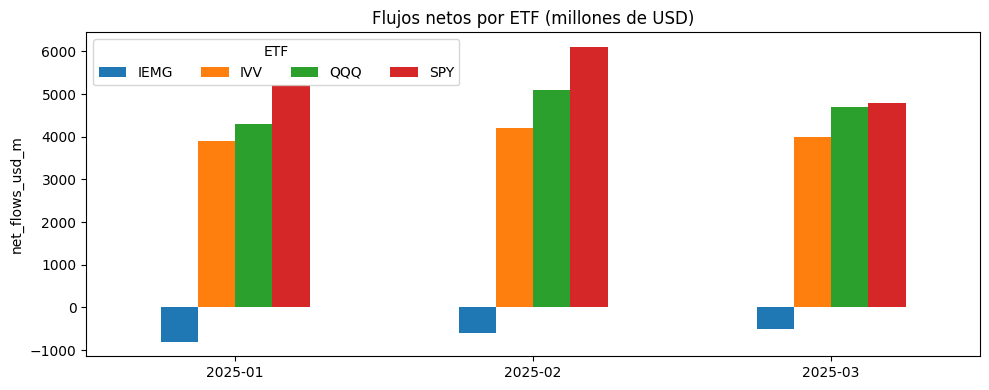

flujo neto total del periodo: 40,400 millones de USD
el ETF con mas flujo concentra el 39.9% del total


,flujo_total,meses
etf_ticker,,
SPY,16100,3
QQQ,14100,3
IVV,12100,3
IEMG,-1900,3


In [3]:
df["mes"] = df["date"].dt.strftime("%Y-%m")
pivote = df.pivot_table(index="mes", columns="etf_ticker",
                        values="net_flows_usd_m", aggfunc="sum")

ax = pivote.plot(kind="bar", figsize=(10, 4))
ax.set_title("Flujos netos por ETF (millones de USD)")
ax.set_ylabel("net_flows_usd_m")
ax.set_xlabel("")
ax.legend(title="ETF", ncols=len(pivote.columns))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

resumen = (df.groupby("etf_ticker")["net_flows_usd_m"]
             .agg(flujo_total="sum", meses="count")
             .sort_values("flujo_total", ascending=False))
print(f"flujo neto total del periodo: {df['net_flows_usd_m'].sum():,.0f} millones de USD")
print("el ETF con mas flujo concentra el "
      f"{resumen['flujo_total'].iloc[0] / df['net_flows_usd_m'].sum() * 100:.1f}% del total")
resumen